# 03 — Pilot: hai baseline và LSTM Autoencoder

Phần tiền xử lý đã được review và được phép huấn luyện một pilot với cấu hình đã
định. Notebook chạy trong kernel mới **Python (LSTM .venv)**; interpreter bắt buộc
`D:\LSTM\.venv\Scripts\python.exe`. Không cài package trong notebook.

Giữ NAB artificial pair, normal 8/3/3 ngày, scaler train-only, cửa sổ 288/stride 1,
nhãn endpoint trên đúng 3.745 điểm test. Mỗi phương pháp có ngưỡng calibration
normal 99%, `method='higher'`, quyết định `score > threshold`. Không dùng test chọn
checkpoint, cấu hình hoặc ngưỡng; không point adjustment. Không tự tuning theo kết quả.

**Cảnh báo diễn giải:** đây là pilot trên dữ liệu nhân tạo, có một sự kiện và khoảng
nhãn dung sai NAB. Metric điểm không phải điểm NAB chính thức hoặc kết luận tổng quát.
Hai chuỗi có timestamp trùng nhau nhưng là hai nguồn độc lập. Test đã được xem để
audit ở giai đoạn 1; cấu hình hiện tại được khóa trước khi huấn luyện.

In [1]:
from pathlib import Path
import sys, os, json, time, platform
from datetime import datetime, timezone
EXPECTED_PYTHON = Path(r'D:\LSTM\.venv\Scripts\python.exe')
print('sys.executable:', sys.executable)
assert Path(sys.executable).resolve() == EXPECTED_PYTHON.resolve()
assert sys.prefix != sys.base_prefix
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src'/'utils.py').is_file())
sys.path.insert(0, str(ROOT))
from src.utils import (download_nab, NORMAL, TEST, sha256, seed_pilot, timestamp_slots,
                       fit_pilot_baselines, baseline_reconstruct, LSTMAutoencoder,
                       train_pilot_lstm, reconstruct_lstm, endpoint_mse,
                       normal_threshold, endpoint_metrics)
RESULTS = ROOT/'results'
PROCESSED = ROOT/'data'/'processed'
pilot_started = time.perf_counter()
seed_pilot(42)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
probe = torch.tensor([1., 2.], device=device)
assert (probe.square().sum().item()) == 5.
environment = {
    'sys_executable': sys.executable, 'python': platform.python_version(),
    'torch': str(torch.__version__), 'numpy': np.__version__, 'pandas': pd.__version__,
    'device': str(device), 'device_name': torch.cuda.get_device_name(0) if device.type=='cuda' else platform.processor(),
    'cuda_runtime': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
    'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory if device.type=='cuda' else None,
    'deterministic_algorithms': torch.are_deterministic_algorithms_enabled(),
    'cudnn_benchmark': torch.backends.cudnn.benchmark,
    'cudnn_deterministic': torch.backends.cudnn.deterministic,
    'tf32': torch.backends.cuda.matmul.allow_tf32, 'cpu_threads': torch.get_num_threads(),
}
display(environment)

sys.executable: D:\LSTM\.venv\Scripts\python.exe


{'sys_executable': 'D:\\LSTM\\.venv\\Scripts\\python.exe',
 'python': '3.12.10',
 'torch': '2.7.1+cu126',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'device': 'cuda:0',
 'device_name': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU',
 'cuda_runtime': '12.6',
 'cudnn': 90701,
 'gpu_memory_bytes': 4294443008,
 'deterministic_algorithms': True,
 'cudnn_benchmark': False,
 'cudnn_deterministic': True,
 'tf32': False,
 'cpu_threads': 4}

## Xác minh dữ liệu và khóa cấu hình

Đọc artifact đã review, kiểm tra hash nguồn và đối chiếu scaler bằng thống kê train
gốc. Nạp train/validation cho huấn luyện; calibration chỉ nạp sau khi đã khóa checkpoint;
test chỉ nạp score sau khi đã chốt ngưỡng. Timestamp gốc dùng cho baseline mùa vụ,
không lấy số thứ tự cửa sổ làm pha ngày. Artifact tiền xử lý không được ghi lại.

PyTorch CUDA 12.6 được cài từ [wheel chính thức bản 2.7.1](https://pytorch.org/get-started/previous-versions/#v2-7-1).
Thiết lập seed 42, cuDNN deterministic, tắt benchmark/TF32 và bật deterministic
algorithms theo [hướng dẫn tái lập](https://docs.pytorch.org/docs/stable/notes/randomness.html).
Không cam kết kết quả bitwise giữa các phần cứng hoặc phiên bản thư viện khác nhau.

In [2]:
raw, manifest = download_nab(ROOT)
rows = pd.read_csv(PROCESSED/'split_rows.csv', parse_dates=['timestamp'])
mapping = pd.read_csv(PROCESSED/'window_mapping.csv', parse_dates=['timestamp_start', 'timestamp_end'])
scaler_state = json.loads((PROCESSED/'scaler.json').read_text())
maps = {name: mapping.loc[mapping.split.eq(name)].reset_index(drop=True)
        for name in ['train', 'validation', 'calibration', 'test']}
train_rows = rows.loc[rows.split.eq('train')].reset_index(drop=True)
assert len(train_rows) == 2304 and train_rows.label.eq(0).all()
assert train_rows.source_id.eq(NORMAL).all()
np.testing.assert_array_equal(train_rows.source_row, np.arange(2304))
assert scaler_state['fit_split'] == 'train' and scaler_state['n_samples_seen'] == 2304
np.testing.assert_allclose(scaler_state['mean'], [train_rows.value.mean()])
np.testing.assert_allclose(scaler_state['scale'], [train_rows.value.std(ddof=0)])
with np.load(PROCESSED/'windows.npz', allow_pickle=False) as archive:
    X_train, X_val = archive['X_train'], archive['X_validation']
    assert not archive['y_endpoint_train'].any() and not archive['y_endpoint_validation'].any()
assert X_train.shape == (2017, 288, 1) and X_val.shape == (577, 288, 1)
for name, x in [('train', X_train), ('validation', X_val)]:
    f = rows.loc[rows.split.eq(name)].reset_index(drop=True)
    values = ((f.value.to_numpy()-scaler_state['mean'][0])/scaler_state['scale'][0]).astype(np.float32)
    for j, m in maps[name].iterrows():
        np.testing.assert_array_equal(x[j, :, 0], values[int(m.local_start):int(m.local_end)+1])
    assert f.label.eq(0).all()

config = {
    'seed': 42, 'length': 288, 'stride': 1, 'features': 1, 'hidden': 32,
    'architecture': 'LSTM(1,32) -> final hidden -> repeat(288) -> LSTM(32,32) -> Linear(32,1)',
    'teacher_forcing': False, 'input_shortcut': False, 'decoder_initial_state': 'zeros',
    'loss': 'full-window MSE', 'optimizer': 'Adam', 'learning_rate': .001,
    'batch_size': 32, 'max_epochs': 50, 'shuffle': False, 'patience': 5, 'min_delta': 0.,
    'restore_best_weights': True, 'selection': 'validation full-window MSE only',
    'normal_split_days': [8, 3, 3], 'score': 'endpoint feature-mean MSE',
    'threshold_quantile': .99, 'threshold_method': 'higher', 'prediction_comparison': '>',
    'test_points': 3745, 'point_adjustment': False, 'dataset_commit': manifest['commit'],
    'preprocessing_hashes': {p.name: sha256(p) for p in PROCESSED.iterdir() if p.is_file()},
    'utils_sha256': sha256(ROOT/'src'/'utils.py'),
}
config_path = RESULTS/'pilot_config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, 'Existing pilot has a different config; stop for review'
else:
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
checks = {'environment': 'PASS: dedicated .venv, tensor device smoke check',
          'preprocessing': 'PASS: train-only scaler and every train/validation window matches original rows'}
display(config)

{'seed': 42,
 'length': 288,
 'stride': 1,
 'features': 1,
 'hidden': 32,
 'architecture': 'LSTM(1,32) -> final hidden -> repeat(288) -> LSTM(32,32) -> Linear(32,1)',
 'teacher_forcing': False,
 'input_shortcut': False,
 'decoder_initial_state': 'zeros',
 'loss': 'full-window MSE',
 'optimizer': 'Adam',
 'learning_rate': 0.001,
 'batch_size': 32,
 'max_epochs': 50,
 'shuffle': False,
 'patience': 5,
 'min_delta': 0.0,
 'restore_best_weights': True,
 'selection': 'validation full-window MSE only',
 'normal_split_days': [8, 3, 3],
 'score': 'endpoint feature-mean MSE',
 'threshold_quantile': 0.99,
 'threshold_method': 'higher',
 'prediction_comparison': '>',
 'test_points': 3745,
 'point_adjustment': False,
 'dataset_commit': 'ea702d75cc2258d9d7dd35ca8e5e2539d71f3140',
 'preprocessing_hashes': {'scaler.json': '8b5e4a4cc2d5a920b1741ea28499f1160b59db8817e30e63263625662e460767',
  'split_rows.csv': '6760ab1dd6e7f29809c8a55d1a0d91955cd210ff3cf0f7fe8a1cf9fdef888ad3',
  'windows.npz': '7ceb785

## Fit hai baseline chỉ trên train

**Train mean:** tái tạo hằng bằng trung bình 2.304 điểm train gốc. **Seasonal median:**
288 median riêng theo slot `hour*12 + minute//5` của timestamp gốc; mỗi slot có đúng
8 quan sát train. Bảng baseline lưu trong đơn vị đã chuẩn hóa train; đó là phép biến
đổi affine của mean/median dữ liệu gốc. Không fit trên các cửa sổ đã nhân bản điểm,
không lấy median hoặc giá trị từ calibration/test làm template.

In [3]:
baseline_state = fit_pilot_baselines(train_rows, scaler_state)
assert baseline_state['fit_rows'] == 2304 and baseline_state['fit_source_rows'] == [0, 2303]
assert len(baseline_state['median_scaled_by_slot']) == 288
assert baseline_state['slot_counts'] == [8]*288
slots = timestamp_slots(train_rows.timestamp)
for slot in range(288):
    raw_median = np.median(train_rows.loc[slots==slot, 'value'])
    np.testing.assert_allclose(baseline_state['median_scaled_by_slot'][slot],
                               (raw_median-scaler_state['mean'][0])/scaler_state['scale'][0], atol=1e-12)
(RESULTS/'pilot_baselines.json').write_text(json.dumps(baseline_state, indent=2), encoding='utf-8')
checks['baseline_fit'] = 'PASS: mean and all 288 slot medians use unique normal train rows only; eight per slot'
print(checks['baseline_fit'])
print('Mean reconstruction in scaled units:', baseline_state['mean_scaled'])

PASS: mean and all 288 slot medians use unique normal train rows only; eight per slot
Mean reconstruction in scaled units: 7.093091546216277e-17


## Một lần huấn luyện LSTM, chỉ chọn bằng validation

Encoder 32 units chỉ truyền vector hidden cuối (32 chiều). Decoder nhận 288 bản sao
của vector này, hidden/cell ban đầu bằng 0, rồi Linear ra một biến mỗi bước. Không
teacher forcing, không truyền input trực tiếp tới output. MSE huấn luyện được tính
trên toàn cửa sổ; validation MSE cũng trên toàn cửa sổ và được cân theo số phần tử,
kể cả batch cuối không đủ 32.

Adam lr 0.001, batch 32, không shuffle, tối đa 50 epoch. Cải thiện là validation MSE
giảm nghiêm ngặt (`min_delta=0`); dừng sau 5 epoch liên tiếp không cải thiện, khôi phục
checkpoint tốt nhất. Không scheduler, clipping, dropout, AMP hoặc thay cấu hình theo test.
Khi chạy lại notebook, chỉ dùng lại pilot hoàn chỉnh cùng cấu hình; không tự huấn luyện lại.

In [4]:
summary_path = RESULTS/'pilot_training_summary.json'
checkpoint_path = RESULTS/'pilot_best.pt'
if checkpoint_path.exists():
    assert summary_path.exists(), 'Incomplete prior pilot; inspect artifacts before another run'
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    assert checkpoint['config'] == config
    model = LSTMAutoencoder(config['length'], config['features'], config['hidden']).to(device)
    model.load_state_dict(checkpoint['state_dict'])
    model.eval().requires_grad_(False)
    history = pd.read_csv(RESULTS/'pilot_history.csv')
    training_summary = json.loads(summary_path.read_text())
    print('Reusing existing completed pilot; no retraining.')
else:
    model, history, training_summary = train_pilot_lstm(X_train, X_val, config, device, RESULTS)
    summary_path.write_text(json.dumps(training_summary, indent=2), encoding='utf-8')
assert training_summary['best_epoch'] == int(history.loc[history.validation_mse.idxmin(), 'epoch'])
assert training_summary['epochs_run'] <= 50
if training_summary['stopped_early']:
    assert int(history.bad_epochs.iloc[-1]) == 5
assert not model.training and all(not p.requires_grad for p in model.parameters())
assert np.isfinite(history[['train_mse','validation_mse']].to_numpy()).all()
print(model)
display(training_summary)
display(history)

Epoch 01: train=1.00110476, val=1.00906323, best=1, stale=0


Epoch 02: train=0.99901845, val=0.99784763, best=2, stale=0


Epoch 03: train=0.99094065, val=0.99314817, best=3, stale=0


Epoch 04: train=0.97461482, val=0.97520331, best=4, stale=0


Epoch 05: train=0.96343241, val=0.97479705, best=5, stale=0


Epoch 06: train=0.95660961, val=0.94307234, best=6, stale=0


... (24 outputs left out)

Epoch 31: train=0.93548356, val=0.93192704, best=26, stale=5


LSTMAutoencoder(
  (encoder): LSTM(1, 32, batch_first=True)
  (decoder): LSTM(32, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


{'best_epoch': 26,
 'best_validation_mse': 0.8829669106357846,
 'epochs_run': 31,
 'training_seconds': 31.476968499999202,
 'stopped_early': True,
 'parameter_count': 12961}

,epoch,train_mse,validation_mse,improved,bad_epochs,seconds
0,1,1.001105,1.009063,True,0,2.013851
1,2,0.999018,0.997848,True,0,0.952848
2,3,0.990941,0.993148,True,0,1.052712
3,4,0.974615,0.975203,True,0,1.077878
4,5,0.963432,0.974797,True,0,0.945544
5,6,0.956610,0.943072,True,0,1.038056
6,7,0.943206,0.935663,True,0,0.944619
7,8,0.936717,0.931078,True,0,1.036911
8,9,0.935429,0.930644,True,0,1.057139
9,10,0.931013,0.926761,True,0,0.832403


In [5]:
# Check actual decoder input with hooks: it must be only the repeated final hidden.
captured = {}
def capture_encoder(module, args, output):
    captured['hidden'] = output[1][0][-1].detach().clone()
def capture_decoder(module, args):
    captured['decoder_input'] = args[0].detach().clone()
    captured['decoder_arg_count'] = len(args)
encoder_hook = model.encoder.register_forward_hook(capture_encoder)
decoder_hook = model.decoder.register_forward_pre_hook(capture_decoder)
with torch.inference_mode():
    shape_probe = model(torch.from_numpy(X_train[:2]).to(device))
encoder_hook.remove()
decoder_hook.remove()
assert tuple(shape_probe.shape) == (2,288,1)
torch.testing.assert_close(captured['decoder_input'], captured['hidden'][:,None,:].repeat(1,288,1), rtol=0, atol=0)
assert captured['decoder_arg_count'] == 1  # no encoder states or teacher-forcing input passed
assert model.decoder.input_size == 32 and model.output.in_features == 32

val_reconstruction = reconstruct_lstm(model, X_val, device, config['batch_size'])
restored_val_mse = float(np.mean((X_val.astype(np.float64)-val_reconstruction.astype(np.float64))**2))
np.testing.assert_allclose(restored_val_mse, training_summary['best_validation_mse'], rtol=1e-5, atol=1e-7)
lock = {'checkpoint': checkpoint_path.name, 'sha256': sha256(checkpoint_path),
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
        'config_sha256': sha256(config_path), 'best_epoch': training_summary['best_epoch'],
        'best_validation_mse': training_summary['best_validation_mse'],
        'restored_validation_mse': restored_val_mse,
        'selection_uses': ['train', 'validation'], 'calibration_or_test_used_for_selection': False}
(RESULTS/'pilot_checkpoint_lock.json').write_text(json.dumps(lock, indent=2), encoding='utf-8')
checks['architecture'] = 'PASS: observed repeated final hidden as only decoder input, correct output shape, no shortcut'
checks['checkpoint_selection'] = 'PASS: minimum validation MSE, early-stop patience, restored weights and recomputed validation loss'
print('CHECKPOINT LOCKED before calibration/test:', lock['sha256'])

CHECKPOINT LOCKED before calibration/test: e1ec787a5268aaaa302458258f6980859c5c111201cc0d8be3ab33060deba8cb


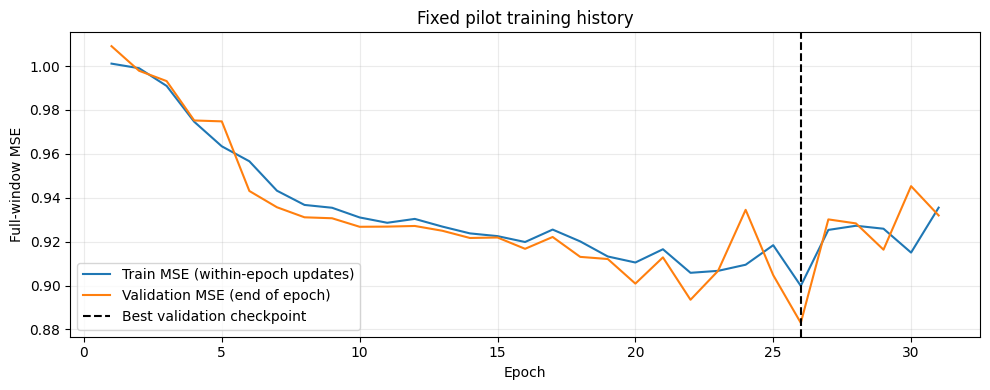

In [6]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(history.epoch, history.train_mse, label='Train MSE (within-epoch updates)')
ax.plot(history.epoch, history.validation_mse, label='Validation MSE (end of epoch)')
ax.axvline(training_summary['best_epoch'], color='black', ls='--', label='Best validation checkpoint')
ax.set(xlabel='Epoch', ylabel='Full-window MSE', title='Fixed pilot training history')
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS/'pilot_loss.png', dpi=160)
plt.show()

## Chọn ba ngưỡng từ calibration normal sau khi khóa checkpoint

Score dùng đúng hàm `endpoint_mse`: mean_feature của bình phương sai số tại điểm
cuối cửa sổ. Không dùng window-MSE để đánh giá, không tổng hợp từ cửa sổ tương lai.
Ngưỡng riêng cho mỗi phương pháp là quantile 99% từ 577 endpoint calibration normal,
với `method='higher'`; dấu so sánh là `>`, không phải `>=`. Không nạp tensor test
để tính ngưỡng. Calibration ngắn và score tương quan nên 1% không phải bảo đảm FPR.

In [7]:
assert sha256(checkpoint_path) == lock['sha256']
with np.load(PROCESSED/'windows.npz', allow_pickle=False) as archive:
    X_cal = archive['X_calibration']
    y_cal = archive['y_endpoint_calibration']
assert X_cal.shape == (577,288,1) and not y_cal.any()
assert maps['calibration'].label_any.eq(0).all()
methods = ['train_mean', 'seasonal_median', 'lstm_autoencoder']
cal_reconstructions = {name: baseline_reconstruct(maps['calibration'], baseline_state, name)
                       for name in methods[:2]}
cal_reconstructions['lstm_autoencoder'] = reconstruct_lstm(model, X_cal, device, config['batch_size'])
cal_scores = {name: endpoint_mse(X_cal, reconstruction) for name, reconstruction in cal_reconstructions.items()}
thresholds = {name: normal_threshold(score, quantile=.99) for name, score in cal_scores.items()}
for name in methods:
    assert np.isfinite(cal_scores[name]).all()
    assert thresholds[name] == float(np.quantile(cal_scores[name], .99, method='higher'))
threshold_record = {'locked_checkpoint_sha256': lock['sha256'],
                    'chosen_at_utc': datetime.now(timezone.utc).isoformat(),
                    'source': 'normal calibration endpoints only', 'n_calibration': 577,
                    'quantile': .99, 'method': 'higher', 'comparison': '>', 'thresholds': thresholds}
(RESULTS/'pilot_thresholds.json').write_text(json.dumps(threshold_record, indent=2), encoding='utf-8')
cal_output = maps['calibration'][['source_id','source_end','timestamp_end','label_endpoint']].rename(
    columns={'source_end':'source_row','timestamp_end':'timestamp','label_endpoint':'label'})
cal_tables = []
for name in methods:
    frame = cal_output.copy()
    frame['method'], frame['score'], frame['threshold'] = name, cal_scores[name], thresholds[name]
    frame['prediction'] = (frame.score>frame.threshold).astype(np.int8)
    cal_tables.append(frame)
pd.concat(cal_tables, ignore_index=True).to_csv(RESULTS/'pilot_calibration_predictions.csv',index=False)
display(pd.DataFrame([{'method': name, 'threshold': thresholds[name],
                       'calibration_predicted_positive': int((cal_scores[name]>thresholds[name]).sum()),
                       'calibration_points':577} for name in methods]))
checks['calibration'] = 'PASS: frozen checkpoint precedes thresholds; each quantile computed only on 577 normal endpoints'

,method,threshold,calibration_predicted_positive,calibration_points
0,train_mean,2.526988,5,577
1,seasonal_median,0.119407,5,577
2,lstm_autoencoder,3.416666,5,577


## Đánh giá duy nhất trên cùng 3.745 endpoint test

Các phương pháp cùng dùng hàng gốc 287–4031, cùng timestamp và cùng nhãn endpoint.
287 điểm đầu là warm-up, không có score/prediction và không tính vào metric.
Average Precision (AP) được tính bằng `average_precision_score` trên score liên tục,
khác diện tích đường PR tính bằng tích phân hình thang. ROC-AUC cũng dùng score liên tục;
Precision/Recall/F1/confusion matrix dùng ngưỡng calibration đã khóa.

In [8]:
assert sha256(checkpoint_path) == lock['sha256']
assert datetime.fromisoformat(lock['locked_at_utc']) <= datetime.fromisoformat(threshold_record['chosen_at_utc'])
test_evaluation_started_utc = datetime.now(timezone.utc).isoformat()
with np.load(PROCESSED/'windows.npz', allow_pickle=False) as archive:
    X_test = archive['X_test']
    y_test = archive['y_endpoint_test']
assert X_test.shape == (3745,288,1) and int(y_test.sum()) == 403
test_map = maps['test']
np.testing.assert_array_equal(test_map.source_end, np.arange(287,4032))
np.testing.assert_array_equal(test_map.label_endpoint, y_test)
assert test_map.source_id.eq(TEST).all()
test_rows = rows.loc[rows.split.eq('test')].reset_index(drop=True)
np.testing.assert_array_equal(test_rows.timestamp.iloc[287:].to_numpy(), test_map.timestamp_end.to_numpy())
np.testing.assert_array_equal(test_rows.label.iloc[287:].to_numpy(), y_test)
test_scaled = ((test_rows.value.to_numpy()-scaler_state['mean'][0])/scaler_state['scale'][0]).astype(np.float32)
for j, row in test_map.iterrows():
    np.testing.assert_array_equal(X_test[j,:,0], test_scaled[int(row.local_start):int(row.local_end)+1])

test_reconstructions = {name: baseline_reconstruct(test_map, baseline_state, name) for name in methods[:2]}
test_reconstructions['lstm_autoencoder'] = reconstruct_lstm(model, X_test, device, config['batch_size'])
test_scores = {name: endpoint_mse(X_test, reconstruction) for name, reconstruction in test_reconstructions.items()}
base_output = test_map[['source_id','source_end','timestamp_end','label_endpoint']].rename(
    columns={'source_end':'source_row','timestamp_end':'timestamp','label_endpoint':'label'})
predictions, metric_records = [], []
for name in methods:
    score = test_scores[name]
    assert score.shape == (3745,) and np.isfinite(score).all()
    frame = base_output.copy()
    frame['method'], frame['score'], frame['threshold'] = name, score, thresholds[name]
    frame['prediction'] = (frame.score>thresholds[name]).astype(np.int8)
    predictions.append(frame)
    metric_records.append({'method':name, **endpoint_metrics(y_test, score, thresholds[name])})
prediction_table = pd.concat(predictions, ignore_index=True)
metrics = pd.DataFrame(metric_records)
prediction_table.to_csv(RESULTS/'pilot_predictions.csv', index=False)
metrics.to_csv(RESULTS/'pilot_metrics.csv', index=False)
display(metrics)
print('Confusion matrix convention: [[TN, FP], [FN, TP]]')
for row in metric_records:
    print(row['method'], [[row['TN'],row['FP']], [row['FN'],row['TP']]])
checks['test_alignment'] = 'PASS: all methods have exactly the same 3745 source rows/timestamps/endpoint labels; 403 positives'
checks['finite_scores'] = 'PASS: finite reconstructions, scores and thresholds for all methods'

,method,Precision,Recall,F1,Average Precision (AP),ROC-AUC,TN,FP,FN,TP,threshold,n_evaluated,n_positive,predicted_positive,predicted_positive_rate
0,train_mean,0.625698,0.277916,0.384880,0.355829,0.519258,3275,67,291,112,2.526988,3745,403,179,0.047797
1,seasonal_median,0.711765,0.300248,0.422339,0.389106,0.579125,3293,49,282,121,0.119407,3745,403,170,0.045394
2,lstm_autoencoder,0.653595,0.248139,0.359712,0.327610,0.502346,3289,53,303,100,3.416666,3745,403,153,0.040854


Confusion matrix convention: [[TN, FP], [FN, TP]]
train_mean [[3275, 67], [291, 112]]
seasonal_median [[3293, 49], [282, 121]]
lstm_autoencoder [[3289, 53], [303, 100]]


## Kiểm tra tải lại checkpoint và quy tắc đánh giá

Tải model mới từ state_dict bằng `weights_only=True`, so toàn bộ reconstruction
calibration và test với model đã khôi phục trong bộ nhớ (rtol 1e-5, atol 1e-6).
Sau đó kiểm tra score và prediction với cùng ngưỡng. Đây là kiểm tra artifact, không
là lần chọn mô hình hoặc lần tuning mới. Hash checkpoint/config/dữ liệu phải giữ nguyên.

In [9]:
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
assert checkpoint['config'] == config and checkpoint['epoch'] == training_summary['best_epoch']
reloaded_model = LSTMAutoencoder(config['length'],config['features'],config['hidden']).to(device)
reloaded_model.load_state_dict(checkpoint['state_dict'])
reloaded_model.eval().requires_grad_(False)
reload_differences = {}
for split_name, data, original_reconstruction in [
    ('calibration',X_cal,cal_reconstructions['lstm_autoencoder']),
    ('test',X_test,test_reconstructions['lstm_autoencoder'])]:
    again = reconstruct_lstm(reloaded_model, data, device, config['batch_size'])
    np.testing.assert_allclose(again, original_reconstruction, rtol=1e-5, atol=1e-6)
    old_scores, new_scores = endpoint_mse(data,original_reconstruction), endpoint_mse(data,again)
    np.testing.assert_allclose(new_scores,old_scores,rtol=1e-5,atol=1e-6)
    np.testing.assert_array_equal(new_scores>thresholds['lstm_autoencoder'],old_scores>thresholds['lstm_autoencoder'])
    reload_differences[split_name] = float(np.max(np.abs(again-original_reconstruction)))

reference_ids = predictions[0][['source_id','source_row','timestamp','label']]
for frame in predictions:
    pd.testing.assert_frame_equal(frame[reference_ids.columns], reference_ids)
    np.testing.assert_array_equal(frame.prediction, (frame.score>frame.threshold).astype(np.int8))
    assert not frame.duplicated(['source_id','source_row']).any()
    assert len(frame) == 3745 and frame.label.sum() == 403
for row in metric_records:
    assert row['TN']+row['FP']+row['FN']+row['TP'] == 3745
    assert row['FN']+row['TP'] == 403
# Verify the seasonal template uses original timestamp endpoint slots in both held-out sets.
for m, reconstruction in [(maps['calibration'],cal_reconstructions['seasonal_median']),
                           (test_map,test_reconstructions['seasonal_median'])]:
    expected = np.asarray(baseline_state['median_scaled_by_slot'],dtype=np.float32)[timestamp_slots(m.timestamp_end)]
    np.testing.assert_array_equal(reconstruction[:,-1,0], expected)
assert sha256(checkpoint_path) == lock['sha256']
assert sha256(config_path) == lock['config_sha256']
assert config['preprocessing_hashes'] == {p.name:sha256(p) for p in PROCESSED.iterdir() if p.is_file()}
read_predictions = pd.read_csv(RESULTS/'pilot_predictions.csv', parse_dates=['timestamp'])
pd.testing.assert_frame_equal(read_predictions, prediction_table, check_dtype=False)
checks['checkpoint_reload'] = 'PASS: full calibration/test reconstructions allclose; identical binary predictions'
checks['prediction_integrity'] = 'PASS: shared endpoints, original timestamp slots, strict >, CSV round-trip, no point adjustment'
checks['frozen_artifacts'] = 'PASS: checkpoint, config and preprocessing hashes unchanged through evaluation'
display(pd.Series(checks))
display(reload_differences)

environment              PASS: dedicated .venv, tensor device smoke check
preprocessing           PASS: train-only scaler and every train/valida...
baseline_fit            PASS: mean and all 288 slot medians use unique...
architecture            PASS: observed repeated final hidden as only d...
checkpoint_selection    PASS: minimum validation MSE, early-stop patie...
calibration             PASS: frozen checkpoint precedes thresholds; e...
test_alignment          PASS: all methods have exactly the same 3745 s...
finite_scores           PASS: finite reconstructions, scores and thres...
checkpoint_reload       PASS: full calibration/test reconstructions al...
prediction_integrity    PASS: shared endpoints, original timestamp slo...
frozen_artifacts        PASS: checkpoint, config and preprocessing has...
dtype: object

{'calibration': 0.0, 'test': 0.0}

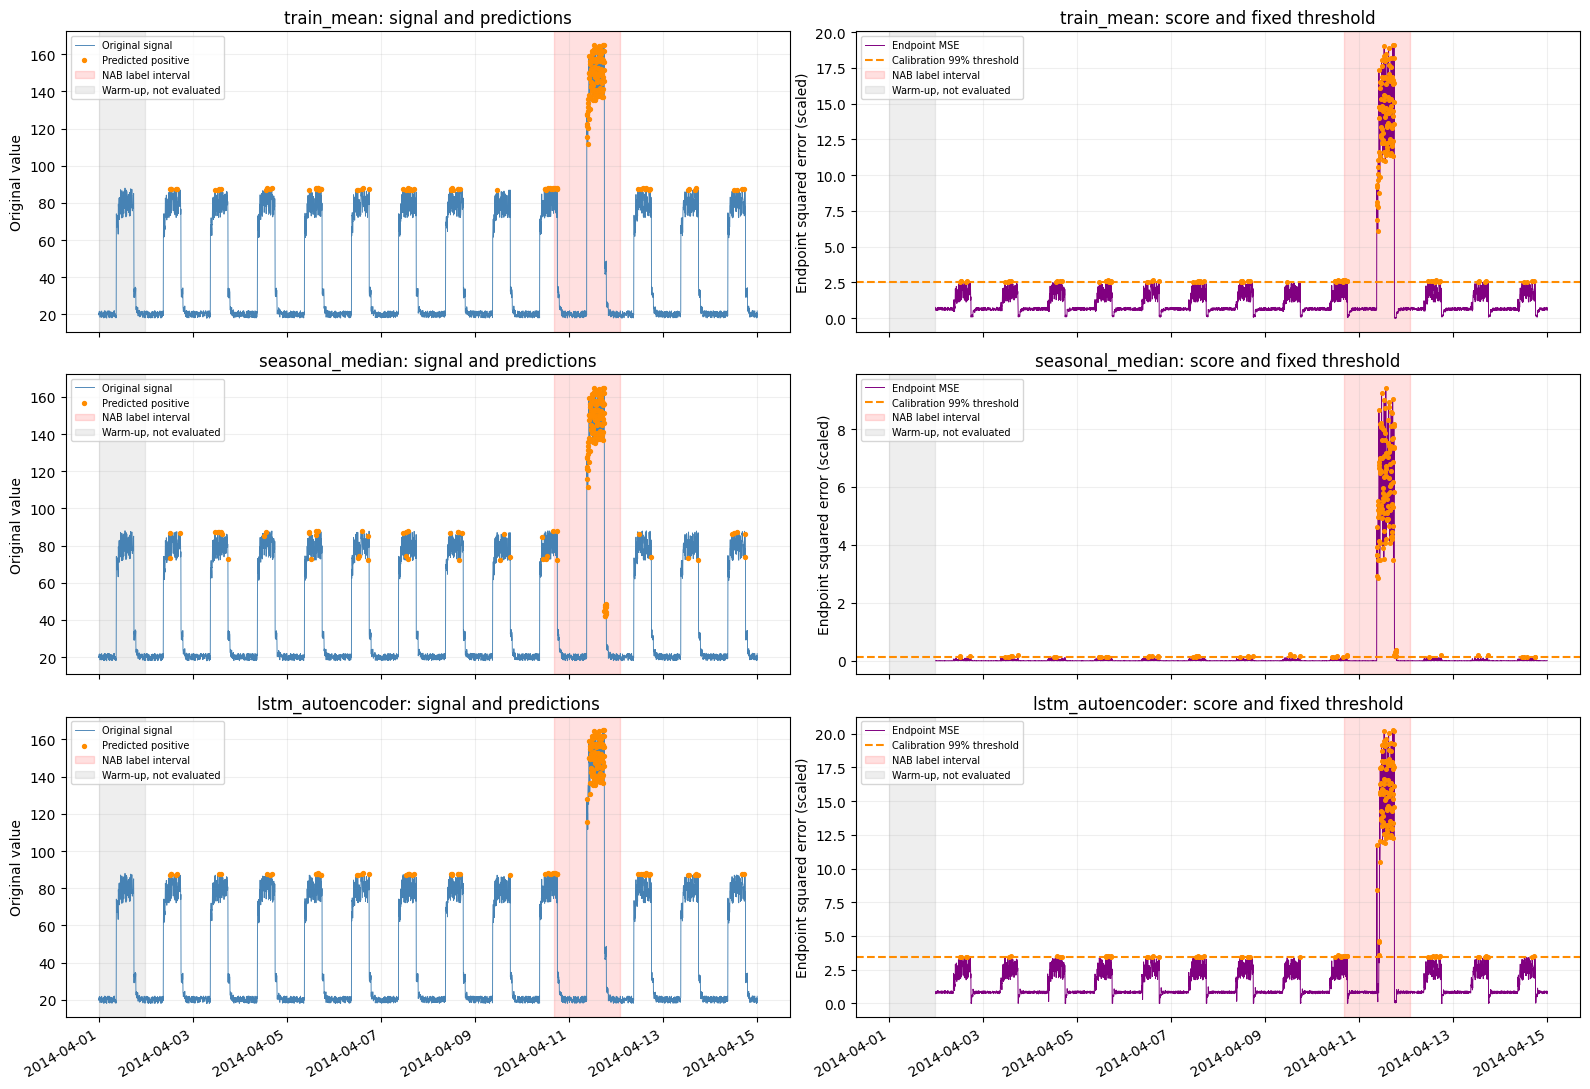

In [10]:
intervals = json.loads((raw/'combined_windows.json').read_text())[TEST]
fig, axes = plt.subplots(3,2,figsize=(16,11),sharex=True)
for i, name in enumerate(methods):
    frame = predictions[i]
    signal_ax, score_ax = axes[i]
    signal_ax.plot(test_rows.timestamp,test_rows.value,lw=.65,color='steelblue',label='Original signal')
    positives = frame.prediction.eq(1)
    predicted_values = test_rows.value.iloc[frame.loc[positives,'source_row'].to_numpy()].to_numpy()
    signal_ax.scatter(frame.loc[positives,'timestamp'],predicted_values,s=8,color='darkorange',label='Predicted positive',zorder=3)
    score_ax.plot(frame.timestamp,frame.score,lw=.7,color='purple',label='Endpoint MSE')
    score_ax.axhline(thresholds[name],color='darkorange',ls='--',label='Calibration 99% threshold')
    score_ax.scatter(frame.loc[positives,'timestamp'],frame.loc[positives,'score'],s=7,color='darkorange',zorder=3)
    for ax in [signal_ax,score_ax]:
        for j,(start,end) in enumerate(intervals):
            ax.axvspan(pd.Timestamp(start),pd.Timestamp(end),color='red',alpha=.12,label='NAB label interval' if j==0 else None)
        ax.axvspan(test_rows.timestamp.iloc[0],test_rows.timestamp.iloc[286],color='grey',alpha=.13,label='Warm-up, not evaluated')
        ax.grid(alpha=.2)
        ax.legend(loc='upper left',fontsize=7)
    signal_ax.set(title=f'{name}: signal and predictions',ylabel='Original value')
    score_ax.set(title=f'{name}: score and fixed threshold',ylabel='Endpoint squared error (scaled)')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(RESULTS/'pilot_detection.png',dpi=160)
plt.show()

## Kết quả thực tế và artifact để review

Các bảng/biểu đồ được sinh từ lần chạy thật, kể cả khi baseline thắng LSTM. Không
đổi kiến trúc, epoch cap, quantile, score hoặc nhãn sau khi thấy test. Nếu một baseline
có AP cao hơn nhưng F1 thấp hơn, cần phân biệt chất lượng xếp hạng với vận hành tại
ngưỡng calibration đã duyệt; không tìm lại ngưỡng theo nhãn test.

`pilot_predictions.csv` chứa ba phương pháp, mỗi phương pháp 3.745 dòng, cột source
row/timestamp/label/score/threshold/prediction; không điền prediction cho warm-up.
`pilot_calibration_predictions.csv` lưu provenance score chọn ngưỡng. Checkpoint `.pt`
được gitignore; config, history, bảng metrics, kiểm tra và PNG lưu trong `results/`.
Thời gian training là wall-clock gồm vòng train/validation và ghi artifact, đã đồng bộ
CUDA; thời gian notebook gồm cả nạp dữ liệu, kiểm tra, inference và vẽ hình, không gồm
thời gian cài package.

In [11]:
pilot_seconds = time.perf_counter()-pilot_started
report = {'environment':environment, 'training':training_summary,
          'notebook_seconds_to_summary':pilot_seconds,
          'checkpoint_lock':lock, 'thresholds':threshold_record,
          'test_evaluation_started_utc':test_evaluation_started_utc,
          'test_points':3745, 'test_positive_points':403, 'test_positive_rate':403/3745,
          'metrics':metric_records, 'checks':checks,
          'checkpoint_reload_max_abs_difference':reload_differences,
          'limitations':['Synthetic NAB pair, single event, not official NAB scoring',
                         'NAB intervals are detection tolerance regions, not exact physical point labels',
                         'Only three calibration days; overlapping scores are correlated',
                         'One fixed configuration and one seed; no generalization claim'],
          'tuning_performed':False, 'point_adjustment':False}
(RESULTS/'pilot_checks.json').write_text(json.dumps({'checks':checks,'reload_max_abs_difference':reload_differences},indent=2),encoding='utf-8')
(RESULTS/'pilot_summary.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
best_f1 = metrics.loc[metrics.F1.idxmax(),'method']
best_ap = metrics.loc[metrics['Average Precision (AP)'].idxmax(),'method']
display(Markdown(f"**Kết quả pilot:** F1 cao nhất: `{best_f1}`; Average Precision (AP) cao nhất: `{best_ap}`. "
                 f"LSTM chọn epoch **{training_summary['best_epoch']}** trong **{training_summary['epochs_run']}** epoch đã chạy. "
                 f"Training: **{training_summary['training_seconds']:.2f} giây**; notebook đến summary: **{pilot_seconds:.2f} giây**. "
                 f"Thiết bị: **{environment['device_name']}**. Dừng để review; chưa mở rộng dataset hoặc viết báo cáo môn học."))
display(metrics)

**Kết quả pilot:** F1 cao nhất: `seasonal_median`; Average Precision (AP) cao nhất: `seasonal_median`. LSTM chọn epoch **26** trong **31** epoch đã chạy. Training: **31.48 giây**; notebook đến summary: **47.01 giây**. Thiết bị: **NVIDIA GeForce RTX 3050 Ti Laptop GPU**. Dừng để review; chưa mở rộng dataset hoặc viết báo cáo môn học.

,method,Precision,Recall,F1,Average Precision (AP),ROC-AUC,TN,FP,FN,TP,threshold,n_evaluated,n_positive,predicted_positive,predicted_positive_rate
0,train_mean,0.625698,0.277916,0.384880,0.355829,0.519258,3275,67,291,112,2.526988,3745,403,179,0.047797
1,seasonal_median,0.711765,0.300248,0.422339,0.389106,0.579125,3293,49,282,121,0.119407,3745,403,170,0.045394
2,lstm_autoencoder,0.653595,0.248139,0.359712,0.327610,0.502346,3289,53,303,100,3.416666,3745,403,153,0.040854
